<a href="https://colab.research.google.com/github/anna-pauliina-p/Datheon_Machine_Learning_-_Data_Science_Internship/blob/main/Task2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Ladda California Housing-datasetet direkt från GitHub CSV URL
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)

# Titta på de första raderna
display(df.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


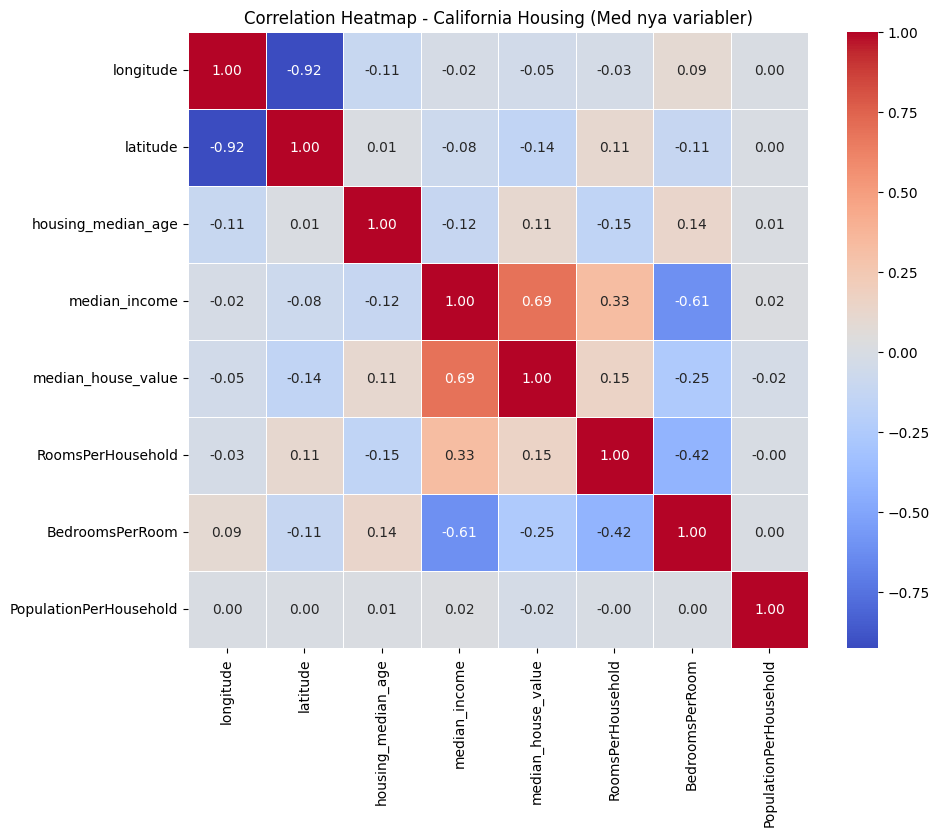

In [17]:
# 1. Gör Feature Engineering direkt på df först
df['RoomsPerHousehold'] = df['total_rooms'] / df['households']
df['BedroomsPerRoom'] = df['total_bedrooms'] / df['total_rooms']
df['PopulationPerHousehold'] = df['population'] / df['households']

# 2. Droppa de gamla råa kolumnerna som orsakade multikollinearitet
df = df.drop(columns=['total_rooms', 'total_bedrooms', 'population', 'households'])

# 3. Imputera saknade värden på det nya, uppdaterade datasetet
imputer = SimpleImputer(strategy='median')
numeric_cols = df.select_dtypes(include=[np.number]).columns
df_numeric_imputed = pd.DataFrame(imputer.fit_transform(df[numeric_cols]), columns=numeric_cols)

# 4. Rita den uppdaterade korrelations-heatmapen
plt.figure(figsize=(10, 8))
corr_matrix = df_numeric_imputed.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap - California Housing (Med nya variabler)')
plt.show()

In [18]:
# 3. Koda kategoriska attribut (ocean_proximity) med One-Hot Encoding
df_encoded = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True)

# Imputera hela det enkodade datasetet om det behövs
df_fully_imputed = pd.DataFrame(imputer.fit_transform(df_encoded), columns=df_encoded.columns)

# Sätt upp X (funktioner) och y (målvariabel: median_house_value)
X = df_fully_imputed.drop(columns=['median_house_value'])
y = df_fully_imputed['median_house_value']

# Dela upp i tränings- och testdata (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardisera kontinuerliga variabler med StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
# 4. Fit OLS, Ridge och Lasso modeller över flera alpha-hyperparametrar med GridSearchCV
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)

ridge = Ridge()
ridge_params = {'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}
ridge_cv = GridSearchCV(ridge, ridge_params, cv=5, scoring='neg_mean_squared_error')
ridge_cv.fit(X_train_scaled, y_train)
best_ridge = ridge_cv.best_estimator_

lasso = Lasso(max_iter=10000)
lasso_params = {'alpha': [0.0001, 0.001, 0.01, 0.1, 1.0]}
lasso_cv = GridSearchCV(lasso, lasso_params, cv=5, scoring='neg_mean_squared_error')
lasso_cv.fit(X_train_scaled, y_train)
best_lasso = lasso_cv.best_estimator_

print("Bästa Ridge alpha:", ridge_cv.best_params_)
print("Bästa Lasso alpha:", lasso_cv.best_params_)

Bästa Ridge alpha: {'alpha': 1.0}
Bästa Lasso alpha: {'alpha': 1.0}


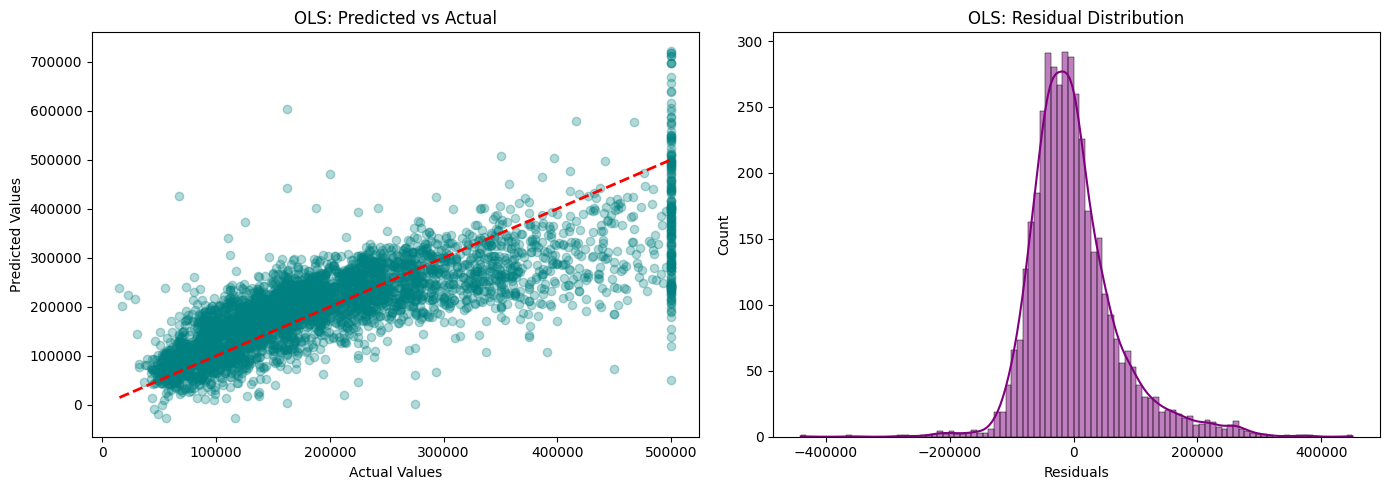

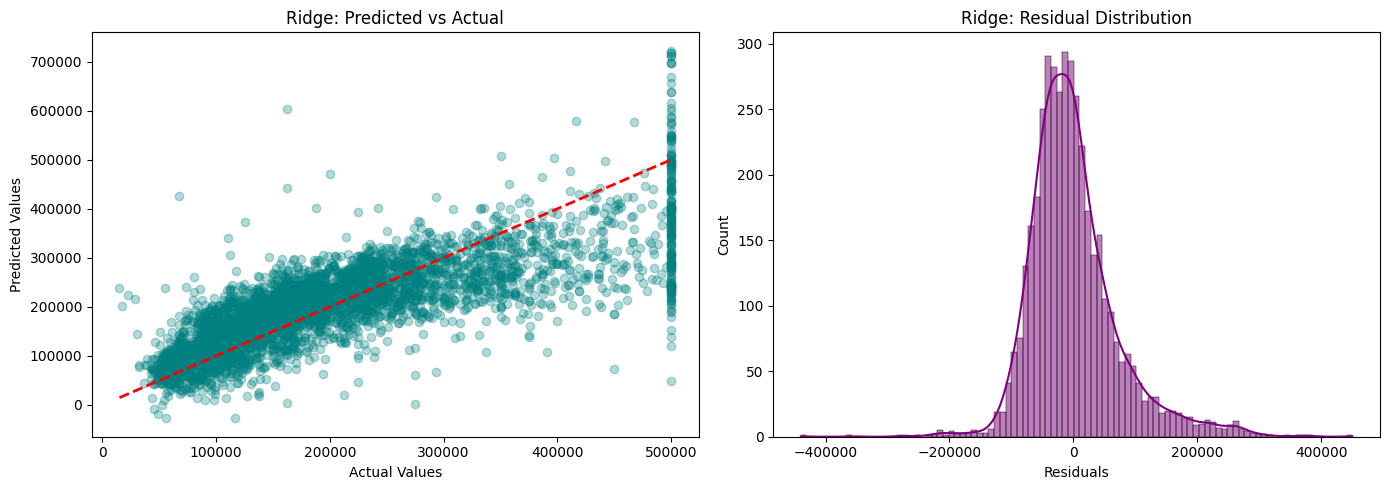

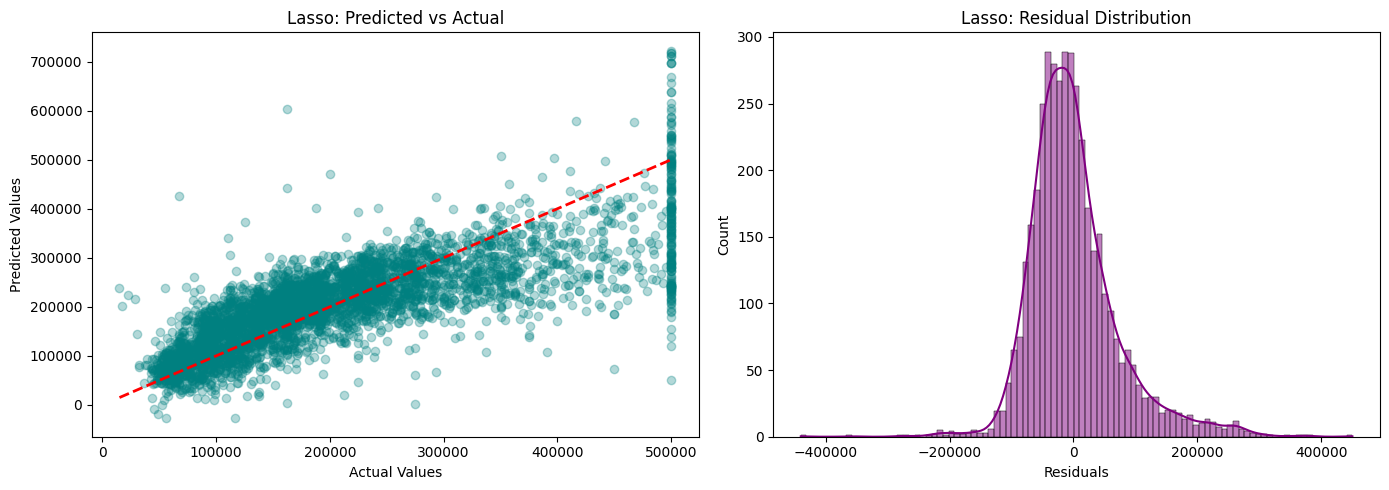

,Model,RMSE,MAE,R2
0,OLS,72044.385501,51608.925179,0.603910
1,Ridge,72043.772270,51607.570852,0.603917
2,Lasso,72044.172255,51608.556801,0.603913


In [21]:
# 5. Utvärdering: Beräkna mätvärden (RMSE, MAE, R2) och plotta grafer
models = {
    "OLS": ols,
    "Ridge": best_ridge,
    "Lasso": best_lasso
}

results = []

for name, model in models.items():
    # Gör prediktioner på testdatan
    y_pred = model.predict(X_test_scaled)

    # Beräkna performance metrics
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({"Model": name, "RMSE": rmse, "MAE": mae, "R2": r2})

    # Skapa visualiseringar för varje modell
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # 1. Predicted vs Actual
    axes[0].scatter(y_test, y_pred, alpha=0.3, color='teal')
    axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[0].set_title(f'{name}: Predicted vs Actual')
    axes[0].set_xlabel('Actual Values')
    axes[0].set_ylabel('Predicted Values')

    # 2. Residual Distribution Curves (Felanalys)
    residuals = y_test - y_pred
    sns.histplot(residuals, kde=True, ax=axes[1], color='purple')
    axes[1].set_title(f'{name}: Residual Distribution')
    axes[1].set_xlabel('Residuals')

    plt.tight_layout()
    plt.show()

# Sammanställ och visa en snygg tabell med alla resultat
results_df = pd.DataFrame(results)
display(results_df)